# 🛵 Projeto Final — Fundamentos de Machine Learning
___

O objetivo deste projeto é colocar em prática os conceitos estudados em sala sobre:

* Pré-processamento de dados
* Aprendizado supervisionado e não supervisionado
* Regressão, classificação e clusterização
* Boas práticas em Machine Learning (overfitting, regularização, PCA, evitar vazamento de informações, tratamento de classes desbalanceadas, etc.)
___
## Tarefa
___

Cada aluno deverá escolher um dataset de sua preferência (ex.: Kaggle, UCI Machine Learning Repository, IBGE, dados sintéticos gerados com IA, entre outros) e desenvolver um projeto de Machine Learning, contendo as seguintes etapas:

1. Descrição do problema a ser resolvido (ex.: previsão, classificação, agrupamento).
2. Pré-processamento dos dados: tratamento de valores ausentes, normalização/transformação, codificação de variáveis, análise exploratória.
3. Definição da tarefa de aprendizado: supervisionado ou não supervisionado.
4. Construção do modelo: escolha de algoritmos adequados (regressão, classificação, clusterização, etc.).
5. Avaliação do modelo: utilização de métricas apropriadas ao problema.
6. Aplicação de boas práticas conforme a necessidade:
    * Evitar overfitting
    * Validação adequada
    * Regularização, quando necessário
    * Tratamento de classes desbalanceadas
    * Evitar vazamento de informações
___
## Observações
___

* O tema e o dataset são de livre escolha de cada aluno.
* O projeto pode ser entregue em formato de notebook (Jupyter/Google Colab) com explicações e códigos ou PDF.
* Lembre-se: mais importante do que a complexidade do modelo é a aplicação correta dos fundamentos que vimos na disciplina.

### 👥 Identificação
✍️ **Componentes do Grupo:**

- **Nome 1:** Haroé Silva
- **Nome 2:** Hélio Brandão
- **Nome 3:** Joadson B. Nunes

## 📖 O contexto

Todo banco deseja reter seus clientes para sustentar o seu negócio; o mesmo ocorre com o **Banco Multinacional ABC.**

Abaixo, apresentam-se os dados dos correntistas do Banco Multinacional ABC; o **objetivo desses dados é prever a rotatividade de clientes (*customer churn*).**


### 📖 Dicionário de dados

| Coluna | Descrição |
| :--- | :--- |
| **`customer_id`** | Identificador único da conta do cliente (Account Number) |
| **`credit_score`** | Pontuação de crédito do cliente (Credit Score) |
| **`country`** | País de residência do cliente (França, Alemanha ou Espanha) |
| **`gender`** | Gênero do cliente (Masculino/Feminino) |
| **`age`** | Idade do cliente (anos) |
| **`tenure`** | Há quantos anos o cliente tem conta no banco |
| **`balance`** | Saldo atual da conta bancária (Account Balance) |
| **`products_number`** | Quantidade de produtos que o cliente contratou do banco |
| **`credit_card`** | O cliente possui cartão de crédito? (1 = Sim / 0 = Não) |
| **`active_member`** | O cliente é um membro ativo do banco? (1 = Sim / 0 = Não) |
| **`estimated_salary`** | Salário anual estimado do cliente |
| **`churn`** | O cliente cancelou a conta e deixou o banco? (1 = Sim / 0 = Não) |


# 1.0 IMPORTS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay
)

### 1.0.1 Helper functions

In [2]:
def avaliar(resultados, nome, y_real, y_previsto, y_prob=None):
    resultados.append({
        'modelo': nome,
        'acurácia': accuracy_score(y_real, y_previsto),
        'precisão': precision_score(y_real, y_previsto, zero_division=0),
        'recall': recall_score(y_real, y_previsto),
        'F1': f1_score(y_real, y_previsto),
        'ROC-AUC': roc_auc_score(y_real, y_prob) if y_prob is not None else np.nan,
    })
    return pd.DataFrame(resultados).round(3)

def relatorio_qualidade(bruto):
    """Resumo de qualidade: tipo, nulos, valores únicos e exemplos de cada coluna."""
    return pd.DataFrame({
        "tipo": bruto.dtypes.astype(str),
        "nulos": bruto.isna().sum(),
        "%_nulos": (bruto.isna().mean() * 100).round(1),
        "valores_unicos": bruto.nunique(),
        "exemplos": [list(bruto[col].dropna().unique()[:5]) for col in bruto.columns],
    })

# 2.0 Dados

In [3]:
ARQUIVOML = 'bank-customer-churn-prediction.csv'
df = pd.read_csv(ARQUIVOML, encoding='utf-8-sig')

print("\n-- Informações gerais do DataFrame:\n")
print(f"Número de linhas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")  

# >>>> Exibindo as primeiras linhas e uma amostra aleatória do DataFrame <<<<
print("\n-- Primeiras linhas do DataFrame:\n")
display(df.head(10))

print("\n-- Amostra aleatória do DataFrame:\n")
display(df.sample(10, random_state=42))

relatorio_qualidade(df)


-- Informações gerais do DataFrame:

Número de linhas: 10000
Número de colunas: 12

-- Primeiras linhas do DataFrame:



,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,15574012,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,15592531,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,15656148,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,15792365,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,15592389,684,France,Male,27,2,134603.88,1,1,1,71725.73,0



-- Amostra aleatória do DataFrame:



,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
6252,15687492,596,Germany,Male,32,3,96709.07,2,0,0,41788.37,0
4684,15736963,623,France,Male,43,1,0.00,2,1,1,146379.30,0
1731,15721730,601,Spain,Female,44,4,0.00,2,1,0,58561.31,0
4742,15762134,506,Germany,Male,59,8,119152.10,2,1,1,170679.74,0
4521,15648898,560,Spain,Female,27,7,124995.98,1,1,1,114669.79,0
6340,15659064,790,Spain,Male,37,8,0.00,2,1,1,149418.41,0
576,15761986,439,Spain,Female,32,3,138901.61,1,1,0,75685.97,0
5202,15713354,597,Germany,Female,22,6,101528.61,1,1,0,70529.00,1
6363,15593454,678,Spain,Female,40,4,113794.22,1,1,0,16618.76,0
439,15690134,464,Germany,Female,42,3,85679.25,1,1,1,164104.74,0


,tipo,nulos,%_nulos,valores_unicos,exemplos
customer_id,int64,0,0.0,10000,"[15634602, 15647311, 15619304, 15701354, 15737..."
credit_score,int64,0,0.0,460,"[619, 608, 502, 699, 850]"
country,str,0,0.0,3,"[France, Spain, Germany]"
gender,str,0,0.0,2,"[Female, Male]"
age,int64,0,0.0,70,"[42, 41, 39, 43, 44]"
tenure,int64,0,0.0,11,"[2, 1, 8, 7, 4]"
balance,float64,0,0.0,6382,"[0.0, 83807.86, 159660.8, 125510.82, 113755.78]"
products_number,int64,0,0.0,4,"[1, 3, 2, 4]"
credit_card,int64,0,0.0,2,"[1, 0]"
active_member,int64,0,0.0,2,"[1, 0]"


In [4]:
# >>>> Exibindo a quantidade de valores duplicados <<<<
duplicados = df.duplicated().sum()

print(f"-- Quantidade de valores duplicados: {duplicados} registros")
display(df[df.duplicated(keep=False)].sort_values('customer_id').head(6))

-- Quantidade de valores duplicados: 0 registros


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn


Coluna desnecessária:
    
- `customer_id`.

In [5]:
df = df.drop(columns=['customer_id'])

## 2.1 Tradução nomes colunas

In [6]:
df.columns = [
    'score_credito',
    'pais',
    'genero',
    'idade',
    'tempo_contrato',
    'saldo',
    'quantidade_produtos',
    'cartao_credito',
    'membro_ativo',
    'salario_estimado',
    'rotatividade'
]

In [7]:
display(df.head())

,score_credito,pais,genero,idade,tempo_contrato,saldo,quantidade_produtos,cartao_credito,membro_ativo,salario_estimado,rotatividade
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2.2 Tipos de dados

In [8]:
# >>>> Exibindo informações sobre os tipos de dados e valores nulos <<<<
print("\n-- Informações sobre os tipos de dados e valores nulos:\n")
display(df.info())


-- Informações sobre os tipos de dados e valores nulos:

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   score_credito        10000 non-null  int64  
 1   pais                 10000 non-null  str    
 2   genero               10000 non-null  str    
 3   idade                10000 non-null  int64  
 4   tempo_contrato       10000 non-null  int64  
 5   saldo                10000 non-null  float64
 6   quantidade_produtos  10000 non-null  int64  
 7   cartao_credito       10000 non-null  int64  
 8   membro_ativo         10000 non-null  int64  
 9   salario_estimado     10000 non-null  float64
 10  rotatividade         10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


None

`pais` e `genero` são atributos de texto que devem ser transformados.

## 2.3 Checagem de nulos e duplicatas

In [9]:
# >>>> Exibindo a quantidade de valores nulos por coluna <<<<
print("\n-- Quantidade de valores nulos por coluna:\n")
display(df.isna().sum())


-- Quantidade de valores nulos por coluna:



score_credito          0
pais                   0
genero                 0
idade                  0
tempo_contrato         0
saldo                  0
quantidade_produtos    0
cartao_credito         0
membro_ativo           0
salario_estimado       0
rotatividade           0
dtype: int64

## 2.4 Exploração dos dados

In [10]:
SUSPEITOS = ["-", "?", "n/a", "na", "null", "none", "sem info", "consulte", "não informado", "", "sem data"]

def procurar_nulos_disfarcados(dados, suspeitos=SUSPEITOS):
    """Conta, em cada coluna, valores de texto que parecem representar 'ausência'."""
    achados = {}
    for col in dados.columns:
        texto = dados[col].dropna().astype(str).str.strip().str.lower()
        contagem = texto[texto.isin(suspeitos)].value_counts()
        if len(contagem) > 0:
            achados[col] = contagem.to_dict()
    return achados

print('\n-- Exibindo dados nulos disfarçados:\n\n', procurar_nulos_disfarcados(df))


-- Exibindo dados nulos disfarçados:

 {}


In [11]:
# >>>>> Relatório de qualidade dos dados <<<<

print('\n-- Exibindo relatório de qualidade:')
diag = pd.DataFrame({
    'faltantes': df.isna().sum(),
    'pct': (df.isna().mean() * 100).round(2),
    'distintos': df.nunique(),
})
diag[diag['faltantes'] > 0].sort_values('faltantes', ascending=False)


-- Exibindo relatório de qualidade:


,faltantes,pct,distintos


In [12]:
# >>>>  Exibindo as estatísticas descritivas (`describe`) e a contagem de valores (`value_counts`) <<<<
print("\n-- Estatísticas descritivas do DataFrame:\n")
display(df[['score_credito', 'tempo_contrato','idade','saldo','quantidade_produtos','cartao_credito','membro_ativo']].describe())


-- Estatísticas descritivas do DataFrame:



,score_credito,tempo_contrato,idade,saldo,quantidade_produtos,cartao_credito,membro_ativo
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,650.528800,5.012800,38.921800,76485.889288,1.530200,0.70550,0.515100
std,96.653299,2.892174,10.487806,62397.405202,0.581654,0.45584,0.499797
min,350.000000,0.000000,18.000000,0.000000,1.000000,0.00000,0.000000
25%,584.000000,3.000000,32.000000,0.000000,1.000000,0.00000,0.000000
50%,652.000000,5.000000,37.000000,97198.540000,1.000000,1.00000,1.000000
75%,718.000000,7.000000,44.000000,127644.240000,2.000000,1.00000,1.000000
max,850.000000,10.000000,92.000000,250898.090000,4.000000,1.00000,1.000000


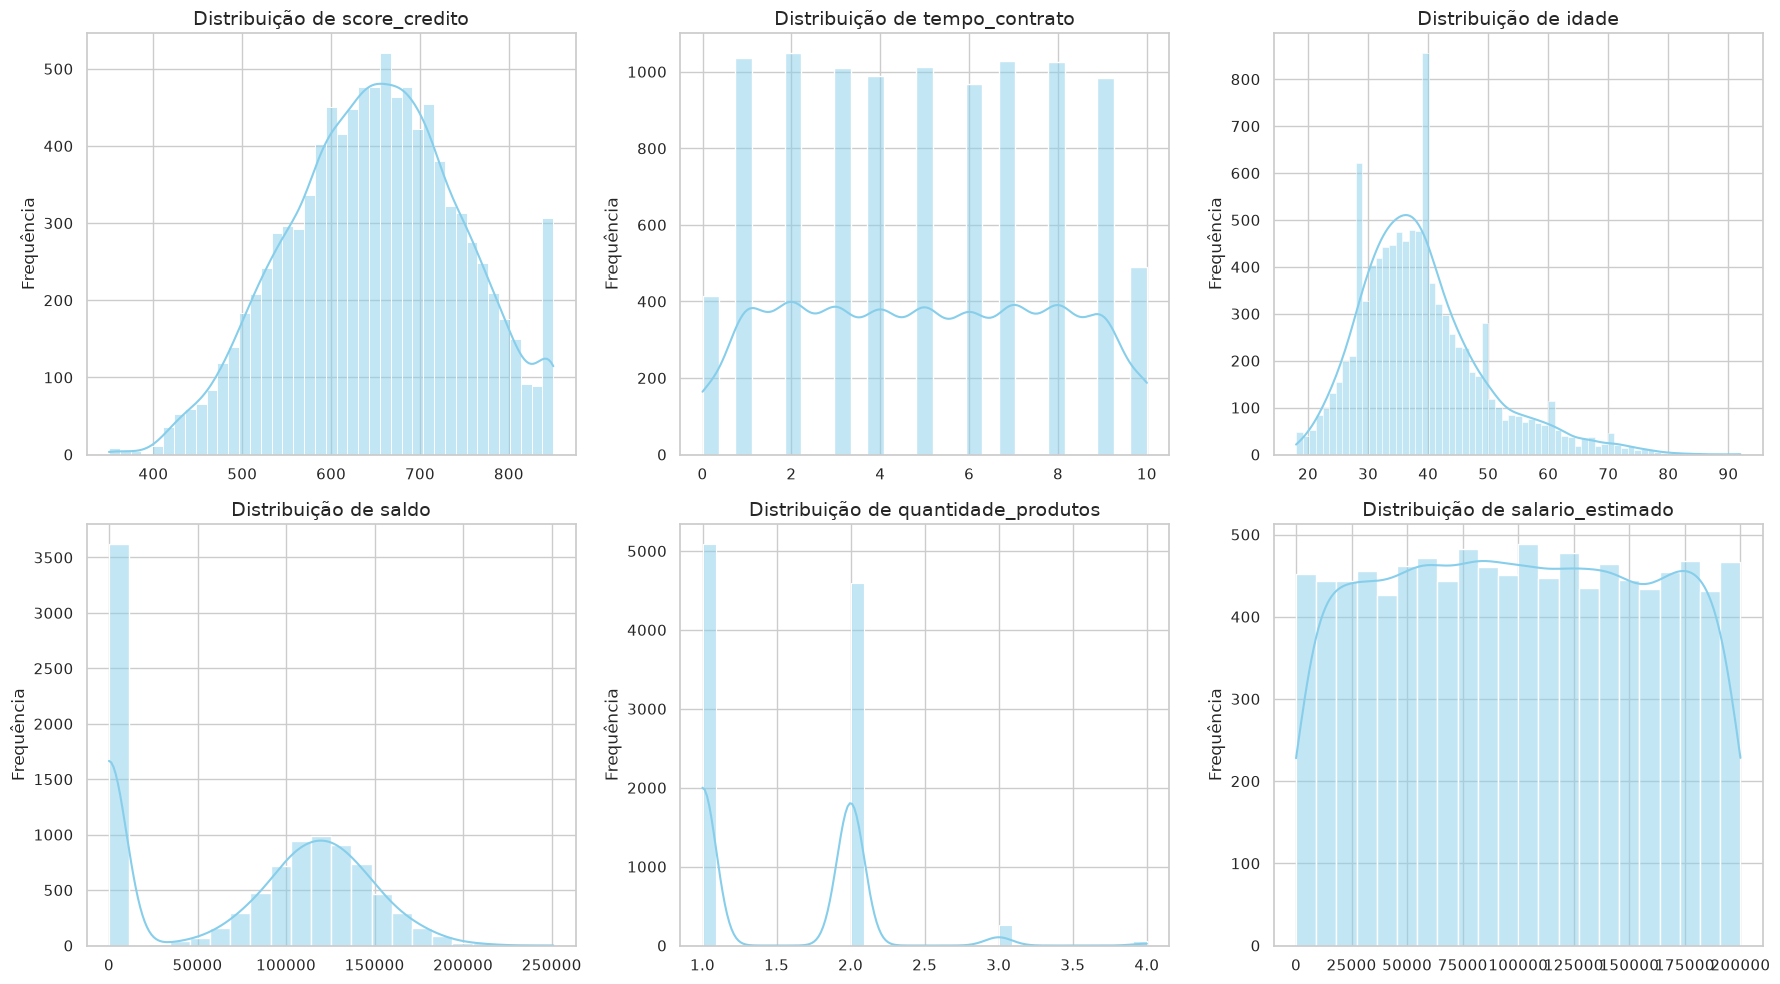

In [13]:
variaveis_quantitativas = ['score_credito', 'tempo_contrato', 'idade', 'saldo', 'quantidade_produtos', 'salario_estimado']

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, coluna in enumerate(variaveis_quantitativas):
    sns.histplot(
        data=df,
        x=coluna,
        kde=True,
        color="skyblue",
        ax=axes[i]
    )
    axes[i].set_title(f'Distribuição de {coluna}', fontsize=14)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

## 2.5 Balanceamento variável alvo

In [14]:
df['rotatividade'].value_counts(normalize=True)

rotatividade
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Cerca de 20% dos clientes abandonaram o banco. As classes são **desbalanceadas**.

## 2.6 Variáveis categóricas

In [15]:
for coluna in df.select_dtypes(exclude='number').columns:
    print(coluna, df[coluna].unique())

pais <StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
genero <StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [16]:
# 1. Criando dicionários mapeando os nomes originais para as traduções
traducao_paises = {
    'France': 'franca',
    'Spain': 'espanha',
    'Germany': 'alemanha'
}
traducao_genero = {
    'Female': 'feminino',
    'Male': 'masculino'
}

# 2. Aplicando as traduções na colunas
df['pais'] = df['pais'].map(traducao_paises)
df['genero'] = df['genero'].map(traducao_genero)

# 3.0 Variáveis categóricas nominais

In [17]:
# pais e genero -> get_dummies
df = pd.get_dummies(
    df, columns=['genero', 'pais'], 
    drop_first=True, dtype=int)

In [18]:
df.columns

Index(['score_credito', 'idade', 'tempo_contrato', 'saldo',
       'quantidade_produtos', 'cartao_credito', 'membro_ativo',
       'salario_estimado', 'rotatividade', 'genero_masculino', 'pais_espanha',
       'pais_franca'],
      dtype='str')

In [19]:
df.head()

,score_credito,idade,tempo_contrato,saldo,quantidade_produtos,cartao_credito,membro_ativo,salario_estimado,rotatividade,genero_masculino,pais_espanha,pais_franca
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,1
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,1
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,1
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


# 4.0 Novas Features

In [20]:

# Flag binária para clientes com saldo zerado
df['sem_saldo'] = (df['saldo'] == 0).astype(int)

In [21]:
# Razão entre o saldo e o salário estimado (proporção da riqueza guardada)
# Somamos 1 ao salário para evitar qualquer divisão por zero acidental
df['proporcao_saldo_salario'] = df['saldo'] / (df['salario_estimado'] + 1)

In [22]:
# Idade combinada com o tempo de contrato (Loyalty Score)
df['idade_por_tempo_contrato'] = df['idade'] * df['tempo_contrato']

print("Novas features criadas com sucesso!")
print(f"Novo formato do DataFrame: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Novas features criadas com sucesso!
Novo formato do DataFrame: 10000 linhas e 15 colunas.


# 5.0 Base final

A base abaixo reúne as variáveis após a limpeza, codificação e criação das novas features. O alvo `rotatividade` será separado dos preditores na etapa de modelagem.

In [23]:
base_final = df.copy()

print(f"Dimensões da base final: {base_final.shape[0]} linhas e {base_final.shape[1]} colunas")
display(base_final.head())

Dimensões da base final: 10000 linhas e 15 colunas


,score_credito,idade,tempo_contrato,saldo,quantidade_produtos,cartao_credito,membro_ativo,salario_estimado,rotatividade,genero_masculino,pais_espanha,pais_franca,sem_saldo,proporcao_saldo_salario,idade_por_tempo_contrato
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,1,1,0.000000,84
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0,0,0.744670,41
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,1,0,1.401362,336
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,1,1,0.000000,39
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0,0,1.587035,86


In [24]:
colunas_numericas = base_final.select_dtypes(include='number')
verificacao_final = pd.DataFrame({
    'tipo': base_final.dtypes.astype(str),
    'valores ausentes': base_final.isna().sum(),
    'valores infinitos': np.isinf(colunas_numericas).sum(),
})
display(verificacao_final)

,tipo,valores ausentes,valores infinitos
score_credito,int64,0,0
idade,int64,0,0
tempo_contrato,int64,0,0
saldo,float64,0,0
quantidade_produtos,int64,0,0
cartao_credito,int64,0,0
membro_ativo,int64,0,0
salario_estimado,float64,0,0
rotatividade,int64,0,0
genero_masculino,int64,0,0


# 6.0 Modelo

O problema é de **classificação supervisionada**: prever `rotatividade` (1 = saiu, 0 = permaneceu). A divisão treino/teste é estratificada para manter a proporção de churn. Como a classe positiva representa cerca de 20% dos dados, além da acurácia vamos observar precisão, recall, F1 e ROC-AUC.

In [25]:
X = base_final.drop(columns=['rotatividade'])
y = base_final['rotatividade']

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Mantemos os DataFrames completos para a análise descritiva abaixo.
treino = X_treino.assign(rotatividade=y_treino)
teste = X_teste.assign(rotatividade=y_teste)

In [26]:
print(f'treino: {len(treino)} clientes ({y_treino.mean():.1%} mudaram de banco)')
print(f'teste: {len(teste)} clientes ({y_teste.mean():.1%} mudaram de banco)')

treino: 8000 clientes (20.4% mudaram de banco)
teste: 2000 clientes (20.3% mudaram de banco)


In [27]:
resultados = []
previsao_base = np.zeros(len(y_teste), dtype=int)
avaliar(resultados, 'Baseline: sempre permanece', y_teste, previsao_base)

modelos = {
    'Regressão logística': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    'KNN (k=5)': make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    'Árvore de decisão': DecisionTreeClassifier(max_depth=5, random_state=42),
}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    y_previsto = modelo.predict(X_teste)
    y_probabilidade = modelo.predict_proba(X_teste)[:, 1]
    avaliar(resultados, nome, y_teste, y_previsto, y_probabilidade)

comparacao = pd.DataFrame(resultados).sort_values('F1', ascending=False).reset_index(drop=True)
display(comparacao)

,modelo,acurácia,precisão,recall,F1,ROC-AUC
0,Árvore de decisão,0.8540,0.804233,0.373464,0.510067,0.838141
1,KNN (k=5),0.8320,0.663594,0.353808,0.461538,0.759668
2,Regressão logística,0.8080,0.589147,0.186732,0.283582,0.774372
3,Baseline: sempre permanece,0.7965,0.000000,0.000000,0.000000,NaN


A tabela abaixo compara médias de algumas variáveis no conjunto de treino. Diferenças entre grupos ajudam a descrever os dados, mas não demonstram uma relação causal.

In [28]:
treino.groupby('rotatividade')[['score_credito', 'tempo_contrato', 'idade', 'saldo', 'quantidade_produtos', 'salario_estimado']].mean().round(1)

,score_credito,tempo_contrato,idade,saldo,quantidade_produtos,salario_estimado
rotatividade,,,,,,
0,652.4,5.0,37.5,72554.1,1.5,99143.3
1,644.3,5.0,44.8,91337.3,1.5,102027.0


,modelo,F1 treino,F1 teste
0,Regressão logística,0.317,0.284
1,KNN (k=5),0.598,0.462
2,Árvore de decisão,0.526,0.510


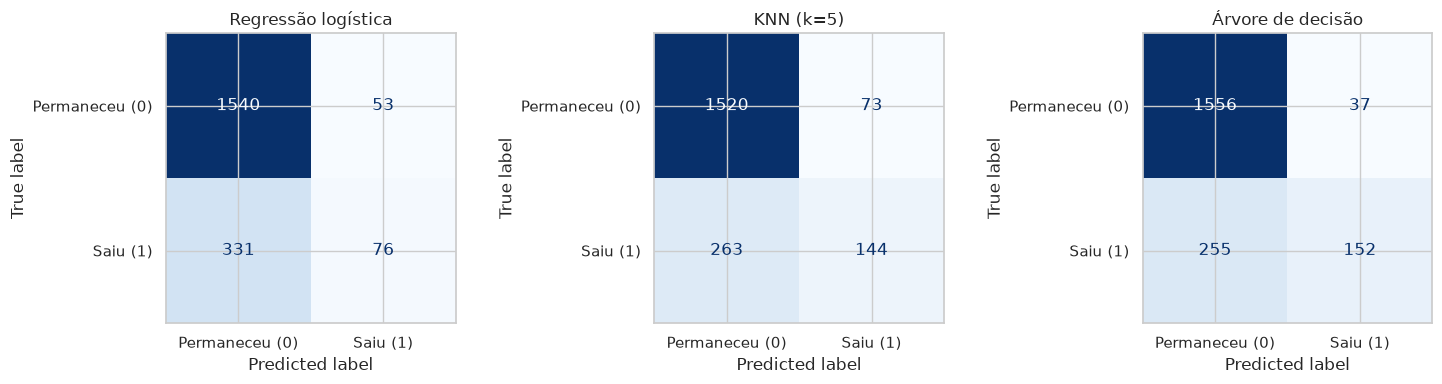

In [29]:
generalizacao = pd.DataFrame([
    {
        'modelo': nome,
        'F1 treino': f1_score(y_treino, modelo.predict(X_treino)),
        'F1 teste': f1_score(y_teste, modelo.predict(X_teste)),
    }
    for nome, modelo in modelos.items()
]).round(3)
display(generalizacao)

fig, axes = plt.subplots(1, len(modelos), figsize=(15, 4))
for ax, (nome, modelo) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_teste,
        y_teste,
        display_labels=['Permaneceu (0)', 'Saiu (1)'],
        cmap='Blues',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(nome)

plt.tight_layout()
plt.show()

## Conclusão

Na divisão de teste, a árvore de decisão teve o melhor F1 (0,510) e ROC-AUC (0,838) entre os modelos comparados, superando o baseline de acurácia 0,797. Ainda assim, seu recall foi 0,373: o modelo identificou pouco mais de um terço dos clientes que saíram. Como a classe de churn é minoritária, a acurácia sozinha não é suficiente para julgar o resultado. Em uma aplicação real, a escolha do modelo e do limiar deve considerar o custo de deixar de identificar clientes em risco e ser confirmada com validação adicional.